# Adversarial examples against a small image classifier

**Module 06 — Adversarial Machine Learning**

This is the notebook where evasion stops being a definition. We train a tiny classifier on 8×8 digit
images, then change pixels by a bounded amount in the direction the model is most sensitive to. The
classifier's accuracy collapses while a human sees the same digit.

## Learning objectives

1. Train a small classifier in PyTorch on CPU and record clean accuracy.
2. Implement the fast gradient sign method (FGSM) and explain each term.
3. Measure accuracy as a function of the perturbation budget ε.
4. Report attack success rate with a denominator and a stated threat model.
5. Explain why "the image looks unchanged" is not a defence.

## Background

FGSM takes one step in the direction that increases the loss, bounded by ε in the $L_\infty$ norm:

$$x' = x + \varepsilon \cdot \operatorname{sign}\big(\nabla_x \ell(f(x), y)\big)$$

The sign means every pixel moves by exactly ε, up or down — the cheapest way to spend an $L_\infty$
budget. Nothing about this is specific to images; the same idea applies to tabular features that an
attacker can influence.

**Threat model used below:** white-box (the attacker has gradients), $L_\infty$ budget up to 0.3 on
inputs scaled to [0, 1], untargeted (any wrong class counts).

## Dependencies and installation

```bash
python -m pip install "torch>=2.4" --index-url https://download.pytorch.org/whl/cpu
python -m pip install "scikit-learn>=1.4" "numpy>=2.1" "matplotlib>=3.9"
```

**CPU only.** The model has about 5k parameters and trains in seconds; no GPU is required or beneficial
at this size. The dataset ships with scikit-learn, so nothing is downloaded.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

SEED = 0
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

digits = load_digits()
X = (digits.images.astype("float32") / 16.0)          # 8x8, scaled to [0, 1]
y = digits.target.astype("int64")

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=SEED, stratify=y)
X_tr, X_te = torch.from_numpy(X_tr), torch.from_numpy(X_te)
y_tr, y_te = torch.from_numpy(y_tr), torch.from_numpy(y_te)

print("train", tuple(X_tr.shape), "test", tuple(X_te.shape), "pixel range", float(X_tr.min()), float(X_tr.max()))

train (1347, 8, 8) test (450, 8, 8) pixel range 0.0 1.0


**Expected output** — 1347 training and 450 test images of shape 8×8, with pixel values in [0, 1]. Small
images keep the whole demonstration inspectable by eye.

### Step 1 — Train the classifier and record clean accuracy

A single hidden layer is enough to be vulnerable; capacity is not the cause of adversarial examples.

In [2]:
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 10),
)
optimiser = torch.optim.Adam(model.parameters(), lr=1e-2)
loss_fn = nn.CrossEntropyLoss()

for epoch in range(12):
    model.train()
    optimiser.zero_grad()
    loss = loss_fn(model(X_tr), y_tr)
    loss.backward()
    optimiser.step()

model.eval()
with torch.no_grad():
    clean_logits = model(X_te)
clean_pred = clean_logits.argmax(dim=1)
clean_acc = float((clean_pred == y_te).float().mean())
print(f"clean test accuracy: {clean_acc:.3f}  (final training loss {float(loss.detach()):.4f})")

clean test accuracy: 0.882  (final training loss 1.0136)


**Expected output** — clean accuracy around 0.88. Full-batch training for 12 epochs is deliberate: it removes optimiser noise so that every later change is attributable to the attack.

### Step 2 — FGSM in nine lines

The gradient is taken **with respect to the input**, not the weights. `torch.autograd.grad` gives it
without touching the parameters, and the sign is what makes the step maximally efficient.

In [3]:
def fgsm(model, x, y, eps):
    x = x.clone().requires_grad_(True)
    loss = loss_fn(model(x), y)
    (grad,) = torch.autograd.grad(loss, x)
    x_adv = x + eps * grad.sign()
    return x_adv.detach().clamp(0, 1)


def accuracy_on(x_adv, y_true):
    with torch.no_grad():
        return float((model(x_adv).argmax(dim=1) == y_true).float().mean())


epsilons = [0.0, 0.05, 0.10, 0.15, 0.20, 0.30]
rows = []
for eps in epsilons:
    x_adv = fgsm(model, X_te, y_te, eps)
    acc = accuracy_on(x_adv, y_te)
    linf = float((x_adv - X_te).abs().max())
    rows.append({"epsilon": eps, "accuracy": round(acc, 3), "L_inf used": round(linf, 3)})

import pandas as pd
pd.DataFrame(rows)

,epsilon,accuracy,L_inf used
0,0.00,0.882,0.00
1,0.05,0.758,0.05
2,0.10,0.553,0.10
3,0.15,0.293,0.15
4,0.20,0.071,0.20
5,0.30,0.000,0.30


**Expected output** — accuracy falls steeply: about 0.88 at ε = 0, roughly 0.55 at ε = 0.10, and under 0.1 by ε = 0.20–0.30. The `L_inf used` column confirms the attack respects its budget, which is the detail
that makes the result interpretable.

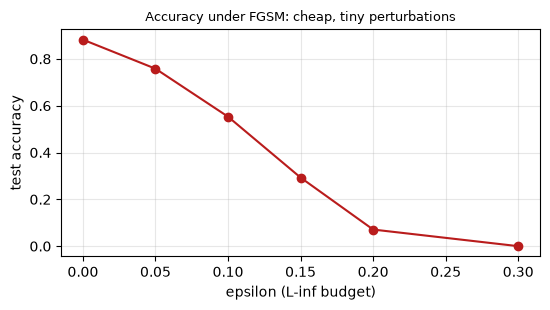

In [4]:
fig, ax = plt.subplots(figsize=(5.6, 3.2))
ax.plot([r["epsilon"] for r in rows], [r["accuracy"] for r in rows], "o-", color="#b91c1c")
ax.set_xlabel("epsilon (L-inf budget)")
ax.set_ylabel("test accuracy")
ax.set_title("Accuracy under FGSM: cheap, tiny perturbations", fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Expected output** — a descending curve that flattens near zero. The steep part is the interesting one:
a budget of 0.1 is 10 % of the pixel range, invisible at this resolution.

### Step 3 — Look at the images, and at what changed

The perturbation is shown amplified 10× so it is visible. What matters is the classifier's answer, not
the visual similarity.

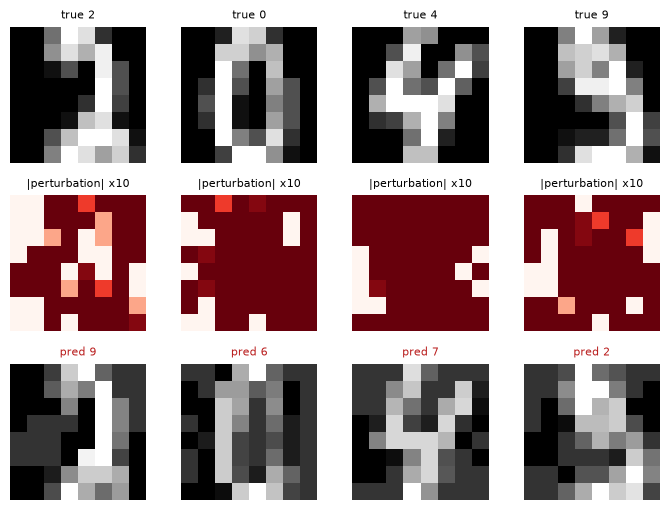

attacked correctly: 32 of 450


In [5]:
x_adv = fgsm(model, X_te, y_te, eps=0.2)
with torch.no_grad():
    adv_pred = model(x_adv).argmax(dim=1)

changed = (adv_pred != y_te).nonzero().flatten()[:4]
fig, axes = plt.subplots(3, 4, figsize=(7, 5.2))
for col, idx in enumerate(changed):
    i = int(idx)
    axes[0, col].imshow(X_te[i].numpy(), cmap="gray")
    axes[0, col].set_title(f"true {int(y_te[i])}", fontsize=8)
    axes[1, col].imshow((x_adv[i] - X_te[i]).abs().numpy() * 10, cmap="Reds")
    axes[1, col].set_title("|perturbation| x10", fontsize=8)
    axes[2, col].imshow(x_adv[i].numpy(), cmap="gray")
    axes[2, col].set_title(f"pred {int(adv_pred[i])}", fontsize=8, color="#b91c1c")
    for row in range(3):
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

print(f"attacked correctly: {int((adv_pred == y_te).sum())} of {len(y_te)}")

**Expected output** — a 3×4 grid: the original digit, the amplified perturbation (a faint pattern, not
noise), and the adversarial image labelled with the wrong class. The perturbation is structured, which is
why random noise of the same size does far less damage (Module 06's second notebook measures that).

### Step 4 — Report the attack properly

A success rate without a threat model is not a result. The summary below states the budget, the access
assumption and the denominator.

In [6]:
n = len(y_te)
successes = int((adv_pred != y_te).sum())
summary = pd.DataFrame(
    [
        {"access": "white-box (gradients)", "norm": "L_inf", "epsilon": 0.2,
         "clean_accuracy": round(clean_acc, 3), "attacked_accuracy": round(accuracy_on(x_adv, y_te), 3),
         "attack_success_rate": round(successes / n, 3), "n": n},
    ]
)
summary

,access,norm,epsilon,clean_accuracy,attacked_accuracy,attack_success_rate,n
0,white-box (gradients),L_inf,0.2,0.882,0.071,0.929,450


**Expected output** — one row with clean accuracy near 0.88, attacked accuracy near 0.07, and ASR near 0.93 over 450 test images. Those four numbers together are the finding; any one alone is marketing.

## Exercises

1. **Targeted attack.** Modify FGSM to push toward a *chosen* class (subtract the target logit from the
   loss) and report success for target class 3.
2. **Compare with random noise.** Add uniform noise with the same $L_\infty$ bound and report accuracy.
   Explain the gap using the gradient.
3. **Change the norm.** Implement an $L_2$ attack by normalising the gradient instead of taking its sign
   and compare success at equal $L_2$ budget.
4. **Attack the training set.** Run FGSM on `X_tr` and measure training accuracy. What does a successful
   attack on training data tell you about the model rather than the attacker?

## Reflection questions

1. The images look identical to you. Who is the "human" in "imperceptible to humans", and what happens
   when the consumer is another model?
2. Why does a 10 % budget cause more damage than doubling the model's size would prevent?
3. Which of the four numbers in the summary would you put in a risk register, and which in an appendix?

## References

1. Goodfellow, I., Shlens, J. and Szegedy, C., "Explaining and Harnessing Adversarial Examples", ICLR 2015.
2. Szegedy, C. et al., "Intriguing properties of neural networks", ICLR 2014.
3. Madry, A. et al., "Towards Deep Learning Models Resistant to Adversarial Attacks", ICLR 2018.
4. Biggio, B. et al., "Evasion attacks against machine learning at test time", ECML PKDD 2013.